
---
date: "2026-10-19"
date-modified: last-modified
format:
  html:
    toc: true
---



# The Division Algorithm for Polynomials

**Prerequisites:** [Rings and Polynomial Rings](rings-and-polynomial-rings.ipynb)

The long division of polynomials learned at school works in great generality: the coefficients may come from any commutative ring, as long as the leading coefficient of the divisor is invertible. The result, division with a remainder of smaller degree, is used to reduce high powers of a matrix via the [Cayley-Hamilton Theorem](cayley-hamilton-theorem.ipynb#cor-power-reduction) and to prove the main property of the [minimal polynomial](minimal-polynomial.ipynb).

Throughout, $R$ is a commutative [ring](rings-and-polynomial-rings.ipynb#def-ring) and $R[x]$ its [polynomial ring](rings-and-polynomial-rings.ipynb#def-polynomial-ring).

## 1\. Statement

::: {#thm-polynomial-division}
## Division with Remainder

Let $p, q \in R[x]$, where $q$ has degree $n$ and its leading coefficient $q_n$ is a **unit** of $R$ (for instance, $q$ is monic). Then there are unique polynomials $s$ (the **quotient**) and $r$ (the **remainder**) with
$$p = s\, q + r \qquad\text{and}\qquad \deg r < \deg q.$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-polynomial-division (Existence)
If $\deg p < n$, take $s = 0$ and $r = p$. In general consider the set
$$\mathcal{S} = \{\, p - t\, q \mid t \in R[x] \,\}.$$
If $0 \in \mathcal{S}$, then $p = s q$ for some $s$, and $r = 0$ works. Otherwise every element of $\mathcal{S}$ has a degree in $\{0, 1, 2, \dots\}$; choose one of **smallest degree**, $r = p - s q$.

Suppose $\deg r = l \ge n$, with leading coefficient $r_l$. The polynomial $r_l\, q_n^{-1} x^{l - n} q$ has degree $l$ and leading coefficient $r_l q_n^{-1} q_n = r_l$; this is where the invertibility of $q_n$ is used. Hence
$$r' = r - r_l\, q_n^{-1} x^{l-n} q$$
has degree less than $l$: the top terms cancel. But $r' = p - (s + r_l q_n^{-1} x^{l-n})\, q \in \mathcal{S}$, which contradicts the minimality of $\deg r$ (or, if $r' = 0$, the assumption $0 \notin \mathcal{S}$). Therefore $\deg r < n$. $\blacksquare$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-polynomial-division (Uniqueness)
If $p = s_1 q + r_1 = s_2 q + r_2$ with $\deg r_1, \deg r_2 < n$, then $(s_1 - s_2)\,q = r_2 - r_1$, a polynomial of degree $< n$ ([degree of a sum](rings-and-polynomial-rings.ipynb#prp-degree-of-sum)). If $s_1 \ne s_2$, then because the leading coefficient of $q$ is a unit, [the degree of the product](rings-and-polynomial-rings.ipynb#prp-degree-of-product) is $\deg(s_1 - s_2) + n \ge n$, a contradiction. So $s_1 = s_2$, and then $r_1 = r_2$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Kill the Top Term, Repeat
The existence proof is long division in disguise: while the current remainder has degree $l \ge n$, subtract the multiple $r_l q_n^{-1} x^{l-n} q$ of $q$ that cancels its top term. Each step lowers the degree, so the process stops, and it can only stop once the degree is below $n$.
:::

::: {#exm-division}
## Dividing in $\mathbb{Z}[x]$

Divide $p = x^5 + 7x^4 + 2x^3 - 3x + 5$ by the monic $q = x^2 + 2x - 1$. The successive quotient terms are $x^3, 5x^2, -7x, 19$, and
$$p = (x^3 + 5x^2 - 7x + 19)\, q + (-48x + 24).$$
All coefficients stay integers because $q$ is monic: only division by $q_n = 1$ occurs. Dividing $4x^3 + 1$ by $3x + 1$ is not possible in $\mathbb{Z}[x]$, but it is in $\mathbb{Q}[x]$, where $3$ is a unit:
$$4x^3 + 1 = \big(\tfrac43 x^2 - \tfrac49 x + \tfrac{4}{27}\big)(3x + 1) + \tfrac{23}{27}.$$
:::

::: {.callout-warning}
## The Leading Coefficient Must Be Invertible
In $\mathbb{Z}[x]$, $x$ cannot be divided by $2x$ with a remainder of degree $< 1$: every $x - s(x) \cdot 2x$ has an odd coefficient of $x$, so it never has degree $0$. The obstruction is exactly that $2$ is not a unit of $\mathbb{Z}$.
:::

::: {#cor-factor-theorem}
## Roots and Linear Factors

Let $K$ be a field, $p \in K[x]$ and $c \in K$. Then $p = (x - c)\, s + p(c)$ for some $s \in K[x]$. In particular $p(c) = 0$ if and only if $x - c$ divides $p$, and a non-zero $p$ of degree $d$ has at most $d$ roots in $K$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-factor-theorem
Divide by the monic $x - c$: $p = (x - c) s + r$ with $\deg r < 1$, so $r$ is a constant. [Evaluating](rings-and-polynomial-rings.ipynb#def-evaluation-map) at $c$ (evaluation is multiplicative over the commutative ring $K$) gives $p(c) = 0 \cdot s(c) + r = r$. If $c_1, \dots, c_k$ are distinct roots, divide off $x - c_1$; the quotient has degree $d - 1$ and still vanishes at $c_2, \dots, c_k$ because $(c_i - c_1) \ne 0$ and $K$ has no zero divisors. By induction $k \le d$. $\blacksquare$
:::

The code runs the division exactly as in the existence proof and records the degree of the running remainder, which drops at every step until it is below $\deg q$.


p = 1x^5 + 7x^4 + 2x^3 + -3x + 5  q = 1x^2 + 2x + -1
   quotient s = 1x^3 + 5x^2 + -7x + 19   remainder r = -48x + 24
p = 4x^3 + 1  q = 3x + 1
   quotient s = 4/3x^2 + -4/9x + 4/27   remainder r = 23/27


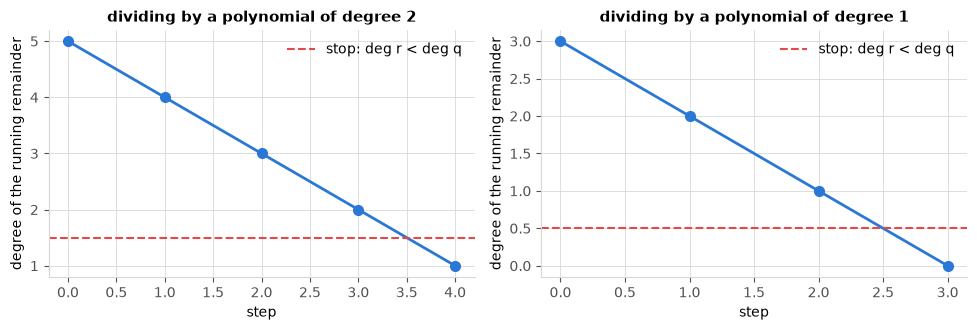

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction

BLUE, RED = "#2a78d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10})

def deg(c):
    nz = [k for k, a in enumerate(c) if a != 0]
    return nz[-1] if nz else -np.inf

def divide(p, q):
    """p, q: coefficient lists (lowest degree first); q's leading coefficient must be invertible."""
    n = int(deg(q)); inv = 1 / Fraction(q[n])
    r = [Fraction(a) for a in p]; s = [Fraction(0)] * max(len(p) - n, 1); history = [deg(r)]
    while deg(r) >= n:
        l = int(deg(r)); t = r[l] * inv                 # r_l q_n^{-1}
        s[l - n] += t
        for j, qj in enumerate(q):
            r[j + l - n] -= t * qj                      # r <- r - t x^{l-n} q
        history.append(deg(r))
    return s, r, history

def show(c):
    terms = [f"{a}" + ("" if k == 0 else "x" if k == 1 else f"x^{k}") for k, a in enumerate(c) if a != 0]
    return " + ".join(reversed(terms)) or "0"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (p, q) in zip(axes, [([5, -3, 0, 2, 7, 1], [-1, 2, 1]), ([1, 0, 0, 4], [1, 3])]):
    s, r, h = divide(p, q)
    print(f"p = {show(p)}  q = {show(q)}\n   quotient s = {show(s)}   remainder r = {show(r[:int(deg(q))])}")
    ax.plot(range(len(h)), [v if v != -np.inf else -0.5 for v in h], "o-", color=BLUE, lw=2, ms=7)
    ax.axhline(deg(q) - 0.5, color=RED, ls="--", lw=1.5, label="stop: deg r < deg q")
    ax.set_xlabel("step"); ax.set_ylabel("degree of the running remainder"); ax.legend()
    ax.set_title(f"dividing by a polynomial of degree {int(deg(q))}")
plt.tight_layout(); plt.show()
